# 2. Boiling point: Chemprop graph neural network

**Workshop goal:** build and assess a compact, reproducible graph-neural-network model that predicts boiling point from a molecule's SMILES string. Chemprop converts each SMILES string into a molecular graph, learns directed bond messages, pools the learned graph representation, and predicts a boiling point.

[![Overview of the Chemprop directed message-passing architecture](https://oscarwumit.github.io/images/chemprop.png)](https://doi.org/10.1021/acs.jcim.3c01250)

*Figure 1. Overview of the Chemprop architecture, from [Heid et al., 2024](https://doi.org/10.1021/acs.jcim.3c01250). The D-MPNN converts atom and bond information into a molecular representation, which a feed-forward network maps to the target property.*

## Workshop workflow

1. Set the workshop run parameters and load the boiling-point data.
2. Use SMILES as the model input and boiling point as the prediction target.
3. Create reproducible training, validation, and held-out test sets.
4. Train a directed message-passing neural network (D-MPNN) with learning-rate scheduling and early stopping.
5. Identify the model from the lowest validation-loss epoch, evaluate it on the held-out test set, and predict a new molecule.

This random split is appropriate for a workshop demonstration. For a claim about performance on new chemical families, participants should next consider a scaffold- or group-aware split. Cross-validation and uncertainty ensembles are intentionally left out so the independent test set stays untouched and the exercise remains CPU-sized.

## Key Chemprop references

1. [Yang et al. (2019), *Analyzing Learned Molecular Representations for Property Prediction*](https://doi.org/10.1021/acs.jcim.9b00237) — foundational directed message-passing model and evaluation study.
2. [Heid et al. (2024), *Chemprop: A Machine Learning Package for Chemical Property Prediction*](https://doi.org/10.1021/acs.jcim.3c01250) — Chemprop architecture and software capabilities.
3. [Graff et al. (2026), *Chemprop v2: An Efficient, Modular Machine Learning Package for Chemical Property Prediction*](https://doi.org/10.1021/acs.jcim.5c02332) — the modern Chemprop v2 implementation used in this workshop.


In [5]:
from pathlib import Path
from importlib.metadata import version
import json
import shutil, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Reproducible experiment configuration
SEED = 42
SAMPLE_SIZE = 4000       # small enough for a workshop CPU run
EPOCHS = 100
BATCH_SIZE = 64
DEPTH = 3
MESSAGE_HIDDEN_DIM = 300
FFN_HIDDEN_DIM = 300
FFN_NUM_LAYERS = 2
DROPOUT = 0.05
ACTIVATION = 'RELU'
LOSS_FUNCTION = 'mse'
METRICS = ['mae', 'rmse', 'r2']
WARMUP_EPOCHS, INIT_LR, MAX_LR, FINAL_LR, PATIENCE = 2, 1e-4, 1e-3, 1e-4, 20
ACQUIRED_DATA_FILE = Path('outputs/nist_acquisition/NIST_BP_SMILES.parquet')
PACKAGED_DATA_FILE = Path('data/CompoundData.parquet')
DATA_FILE = ACQUIRED_DATA_FILE if ACQUIRED_DATA_FILE.exists() else PACKAGED_DATA_FILE
OUTPUT = Path('outputs/bp_chemprop')
FIGURES = OUTPUT / 'figures'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
VERSIONS = {name: version(name) for name in ['chemprop', 'numpy', 'pandas', 'rdkit', 'scikit-learn']}

# 2. Load, inspect, and clean the input table.
raw_data = pd.read_parquet(DATA_FILE).copy()
print(f'Using data source: {DATA_FILE}')
required_columns = {'SMILES', 'BP'}
missing_columns = required_columns - set(raw_data.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
data = raw_data.dropna(subset=['SMILES', 'BP']).drop_duplicates('SMILES')[['SMILES', 'BP']]
data = data.sample(n=min(SAMPLE_SIZE, len(data)), random_state=SEED).reset_index(drop=True)
invalid_smiles = data.SMILES.map(Chem.MolFromSmiles).isna().sum()
if invalid_smiles:
    raise ValueError(f'Sampled data contain {invalid_smiles} invalid SMILES strings.')
print('Feature policy: SMILES only; BP is supplied only as --target-columns (no target-leaking descriptors).')

indices = np.arange(len(data))
train, held_out = train_test_split(indices, test_size=0.20, random_state=SEED)
val, test = train_test_split(held_out, test_size=0.50, random_state=SEED)
data['split'] = 'train'
data.loc[val, 'split'] = 'val'
data.loc[test, 'split'] = 'test'
if set(data['split']) != {'train', 'val', 'test'} or data.SMILES.duplicated().any():
    raise ValueError('Split validation failed: each unique molecule must have exactly one split.')

csv_file = OUTPUT / 'bp_data.csv'
data.to_csv(csv_file, index=False)
split_summary = (
    data.groupby('split')['BP'].agg(n='size', minimum_K='min', mean_K='mean', maximum_K='max')
    .reindex(['train', 'val', 'test'])
)
display(split_summary.round(2))


c:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using data source: outputs\nist_acquisition\NIST_BP_SMILES.parquet
Feature policy: SMILES only; BP is supplied only as --target-columns (no target-leaking descriptors).


,n,minimum_K,mean_K,maximum_K
split,,,,
train,3200,96.50,450.51,721.2
val,400,223.50,445.65,662.2
test,400,81.63,448.61,644.2


In [ ]:
def chemprop_executable():
    executable = shutil.which('chemprop')
    if executable:
        return executable
    windows_candidate = Path(sys.executable).parent / 'Scripts' / 'chemprop.exe'
    if windows_candidate.exists():
        return str(windows_candidate)
    raise RuntimeError('Chemprop was not found. Run `uv sync` in the workshop folder and select the .venv kernel.')


def run_command(command, label='Chemprop command'):
    """Run a quiet Chemprop command; expose its output only if it fails."""
    print(f'{label}...')
    completed = subprocess.run(
        command, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True,
        encoding='utf-8', errors='replace', check=False
    )
    if completed.returncode:
        raise RuntimeError(f'{label} failed.\n{completed.stderr}')


def newest_training_log_dir(model_dir):
    """Return the newest Chemprop training run that contains loss records."""
    log_root = model_dir / 'model_0' / 'trainer_logs'
    runs = [path for path in log_root.glob('version_*') if list(path.glob('events.out.tfevents.*'))]
    if not runs:
        raise FileNotFoundError(f'No Chemprop training-loss records found below {log_root}')
    return max(runs, key=lambda path: path.stat().st_mtime)


def logged_epoch(model_dir, started_at):
    """Read the latest epoch scalar written by the current Chemprop training run."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    try:
        log_dir = newest_training_log_dir(model_dir)
        event_files = list(log_dir.glob('events.out.tfevents.*'))
        newest_event = max(event_files, key=lambda path: path.stat().st_mtime)
        if newest_event.stat().st_mtime < started_at:
            return 0
        accumulator = EventAccumulator(str(newest_event))
        accumulator.Reload()
        epochs = accumulator.Scalars('epoch')
        return int(max(event.value for event in epochs)) + 1 if epochs else 0
    except (FileNotFoundError, KeyError, ValueError, OSError):
        return 0


def run_training_with_progress(command, model_dir, max_epochs):
    """Keep Chemprop quiet and show one live epoch bar in the notebook."""
    print('Training Chemprop model...')
    started_at = time.time()
    process = subprocess.Popen(
        command, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True,
        encoding='utf-8', errors='replace'
    )
    completed_epochs = 0
    with tqdm(total=max_epochs, desc='Chemprop training', unit='epoch') as progress:
        while process.poll() is None:
            current_epoch = min(max_epochs, logged_epoch(model_dir, started_at))
            if current_epoch > completed_epochs:
                progress.update(current_epoch - completed_epochs)
                completed_epochs = current_epoch
            time.sleep(0.5)
        current_epoch = min(max_epochs, logged_epoch(model_dir, started_at))
        if current_epoch > completed_epochs:
            progress.update(current_epoch - completed_epochs)
            completed_epochs = current_epoch
    _, stderr = process.communicate()
    if process.returncode:
        raise RuntimeError(f'Chemprop training failed.\n{stderr}')
    print(f'Chemprop training finished after {completed_epochs} epoch(s).')


def plot_training_loss(tensorboard_log_dir, save_path):
    """Read native Chemprop TensorBoard events and visualize epoch-level loss."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

    event_files = sorted(tensorboard_log_dir.glob('events.out.tfevents.*'), key=lambda path: path.stat().st_mtime)
    accumulator = EventAccumulator(str(event_files[-1]))
    accumulator.Reload()
    available = set(accumulator.Tags().get('scalars', []))
    required = {'epoch', 'train_loss_epoch', 'val_loss'}
    if not required.issubset(available):
        raise RuntimeError(f'Expected loss tags {sorted(required)}; found {sorted(available)}')

    def scalar_frame(tag):
        return pd.DataFrame([(event.step, event.value) for event in accumulator.Scalars(tag)], columns=['step', tag])

    epoch_history = scalar_frame('epoch').drop_duplicates('step', keep='last')
    history = (scalar_frame('train_loss_epoch')
               .merge(scalar_frame('val_loss'), on='step', how='inner')
               .merge(epoch_history, on='step', how='left')
               .dropna(subset=['epoch', 'train_loss_epoch', 'val_loss'])
               [['epoch', 'train_loss_epoch', 'val_loss']]
               .drop_duplicates('epoch', keep='last').sort_values('epoch'))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(history.epoch, history.train_loss_epoch, marker='o', color='#4472C4', label='Train loss')
    ax.plot(history.epoch, history.val_loss, marker='s', color='#C00000', label='Validation loss')
    validation_increases = history.loc[history.val_loss.diff() > 0]
    if not validation_increases.empty:
        ax.scatter(validation_increases.epoch, validation_increases.val_loss, marker='x', s=80, linewidths=2.2,
                   color='#ED7D31', zorder=4, label='Validation loss increased')
    best_row = history.loc[history.val_loss.idxmin()]
    ax.axvline(best_row.epoch, color='#70AD47', linestyle=':', linewidth=2, label='Lowest validation loss')
    ax.scatter(best_row.epoch, best_row.val_loss, s=90, color='#70AD47', zorder=3)
    ax.annotate(f'Best epoch {int(best_row.epoch)}\nval loss = {best_row.val_loss:.4f}',
                xy=(best_row.epoch, best_row.val_loss), xytext=(8, 10), textcoords='offset points', fontsize=9)
    ax.set(xlabel='Epoch', ylabel='Loss (scaled MSE)', title='Chemprop training and validation loss')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(save_path, dpi=250, bbox_inches='tight')
    plt.show()
    print(f'Lowest validation loss: {best_row.val_loss:.4f} at epoch {int(best_row.epoch)}')
    if validation_increases.empty:
        print('Validation loss did not increase between recorded epochs.')
    else:
        epochs = ', '.join(str(int(epoch)) for epoch in validation_increases.epoch)
        print(f'Validation loss increased at epoch(s): {epochs}')
    return history

# 6–10. Chemprop architecture, optimization, loss monitoring, and training.
# Chemprop uses its default Adam optimizer and internally standardizes regression targets from training data.
# No external scaler is fit, preventing validation/test information from entering preprocessing.
model_dir = OUTPUT / 'model'
command = [
    chemprop_executable(), 'train', '-q', '-q',
    '--data-path', str(csv_file), '--smiles-columns', 'SMILES', '--target-columns', 'BP',
    '--task-type', 'regression', '--splits-column', 'split', '--output-dir', str(model_dir),
    '--epochs', str(EPOCHS), '--batch-size', str(BATCH_SIZE), '--depth', str(DEPTH),
    '--message-hidden-dim', str(MESSAGE_HIDDEN_DIM), '--ffn-hidden-dim', str(FFN_HIDDEN_DIM),
    '--ffn-num-layers', str(FFN_NUM_LAYERS), '--dropout', str(DROPOUT), '--activation', ACTIVATION,
    '--loss-function', LOSS_FUNCTION, '--metrics', *METRICS, '--tracking-metric', 'val_loss',
    '--warmup-epochs', str(WARMUP_EPOCHS), '--init-lr', str(INIT_LR), '--max-lr', str(MAX_LR),
    '--final-lr', str(FINAL_LR), '--patience', str(PATIENCE),
    '--pytorch-seed', str(SEED), '--num-workers', '0',
]
run_training_with_progress(command, model_dir, EPOCHS)

training_log_dir = newest_training_log_dir(model_dir)
loss_history = plot_training_loss(training_log_dir, FIGURES / 'loss_vs_epoch.png')
selected_epoch = int(loss_history.loc[loss_history.val_loss.idxmin(), 'epoch'])
best_model_file = model_dir / 'model_0' / 'best.pt'
if not best_model_file.exists():
    raise FileNotFoundError(f'Chemprop best-model file not found: {best_model_file}')
print(f'Final model: {best_model_file}')
print(f'It is selected from epoch {selected_epoch}, where validation loss was lowest.')

prediction_file = OUTPUT / 'predictions.csv'
predict_command = [
    chemprop_executable(), 'predict', '--test-path', str(csv_file), '--smiles-columns', 'SMILES',
    '--model-paths', str(model_dir), '--preds-path', str(prediction_file),
    '--batch-size', '64', '--num-workers', '0',
]
run_command(predict_command, label='Creating test-set predictions')


Training Chemprop model...


Chemprop training:  17%|█▋        | 17/100 [01:56<04:31,  3.27s/epoch] 

,n,MAE (K),RMSE (K),R2
split,,,,
train,1200,7.60,13.83,0.96
val,150,14.35,30.99,0.84
test,150,12.12,19.78,0.91


,n,MAE (K),RMSE (K),R2,Baseline MAE (K),Baseline RMSE (K)
split,,,,,,
train,1200,7.60,13.83,0.96,56.93,71.58
val,150,14.35,30.99,0.84,60.81,76.83
test,150,12.12,19.78,0.91,54.53,67.87


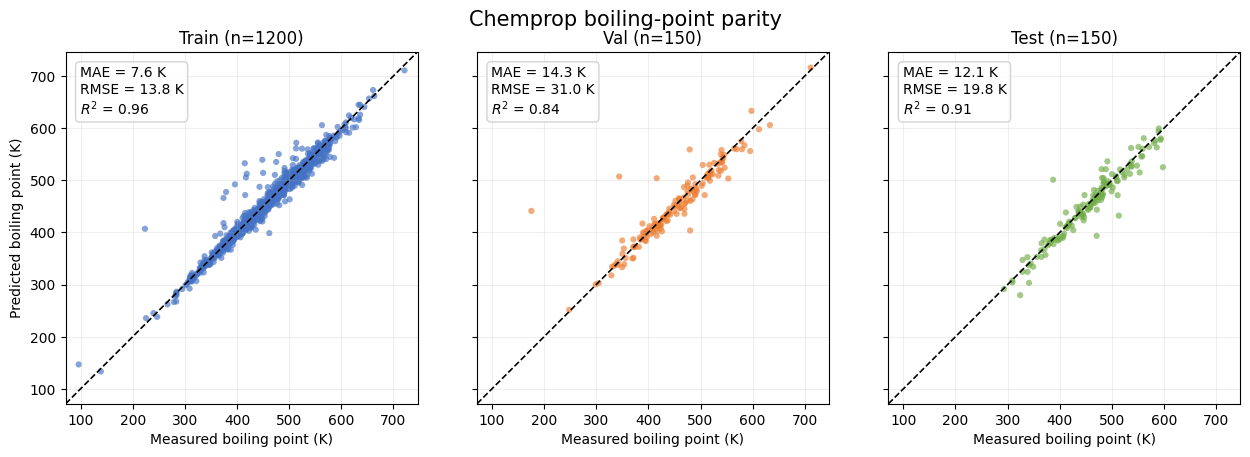

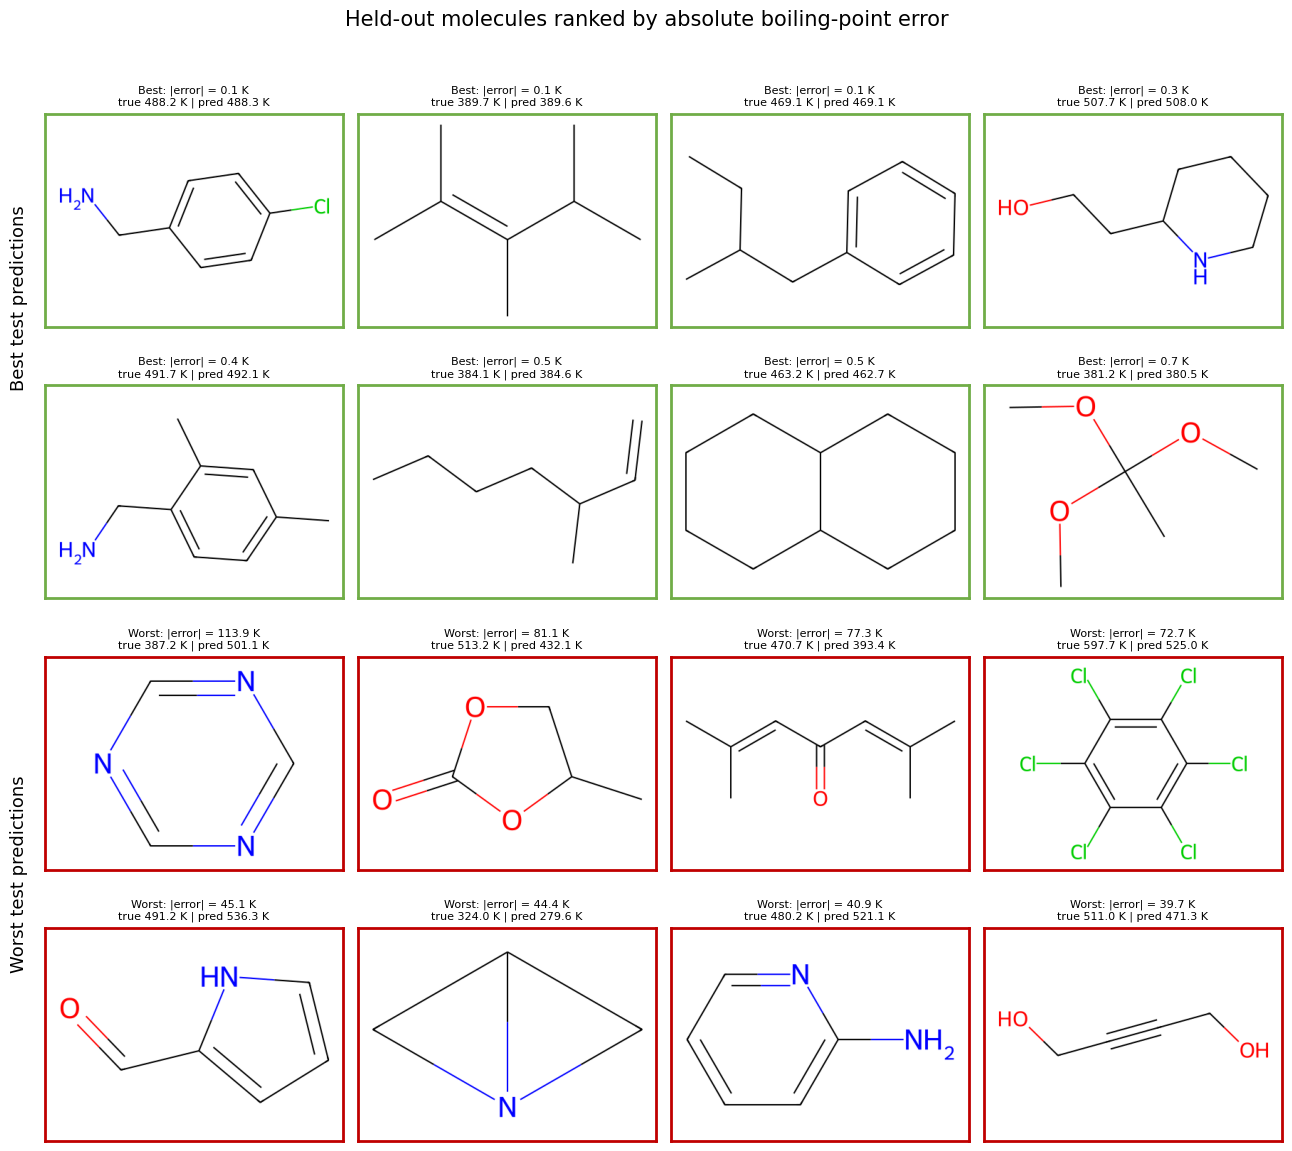

Saved model/checkpoints: outputs\bp_chemprop\model
Saved results and manifest: outputs\bp_chemprop


In [ ]:
predictions = pd.read_csv(prediction_file)
candidate_columns = ['BP_pred', 'pred_0', 'BP']
prediction_column = next((column for column in candidate_columns if column in predictions.columns), None)
if prediction_column is None:
    numeric = predictions.select_dtypes(include='number').columns.tolist()
    if len(numeric) != 1:
        raise ValueError(f'Cannot identify prediction column: {predictions.columns.tolist()}')
    prediction_column = numeric[0]

results = data.copy()
results['predicted_BP'] = predictions[prediction_column].to_numpy()
results['residual_K'] = results.BP - results.predicted_BP
results['absolute_error_K'] = results.residual_K.abs()
results.to_csv(OUTPUT / 'BP_predictions_complete.csv', index=False)

rows = []
for split in ['train', 'val', 'test']:
    subset = results.query('split == @split')
    rows.append({
        'split': split, 'n': len(subset),
        'MAE (K)': mean_absolute_error(subset.BP, subset.predicted_BP),
        'RMSE (K)': mean_squared_error(subset.BP, subset.predicted_BP) ** 0.5,
        'R2': r2_score(subset.BP, subset.predicted_BP),
    })
metrics = pd.DataFrame(rows).set_index('split')
display(metrics.round(2))

# 11. A training-mean baseline makes the learned model's gain explicit.
baseline_bp = results.query("split == 'train'").BP.mean()
baseline_rows = []
for split in ['train', 'val', 'test']:
    subset = results.query('split == @split')
    baseline_rows.append({'split': split, 'Baseline MAE (K)': mean_absolute_error(subset.BP, np.full(len(subset), baseline_bp)),
                          'Baseline RMSE (K)': mean_squared_error(subset.BP, np.full(len(subset), baseline_bp)) ** 0.5})
baseline_metrics = pd.DataFrame(baseline_rows).set_index('split')
comparison = metrics.join(baseline_metrics)
display(comparison.round(2))

colors = {'train': '#4472C4', 'val': '#ED7D31', 'test': '#70AD47'}
values = np.concatenate([results.BP.to_numpy(), results.predicted_BP.to_numpy()])
padding = 0.04 * (values.max() - values.min())
limits = (values.min() - padding, values.max() + padding)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
for ax, split in zip(axes, ['train', 'val', 'test']):
    subset = results.query('split == @split')
    ax.scatter(subset.BP, subset.predicted_BP, s=20, alpha=0.65, color=colors[split], edgecolor='none')
    ax.plot(limits, limits, 'k--', linewidth=1.2)
    ax.set(title=f'{split.title()} (n={len(subset)})', xlabel='Measured boiling point (K)', xlim=limits, ylim=limits)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.20)
    row = metrics.loc[split]
    ax.text(0.04, 0.96, f"MAE = {row['MAE (K)']:.1f} K\nRMSE = {row['RMSE (K)']:.1f} K\n$R^2$ = {row['R2']:.2f}",
            transform=ax.transAxes, va='top', bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.85, 'edgecolor': '0.8'})
axes[0].set_ylabel('Predicted boiling point (K)')
fig.suptitle('Chemprop boiling-point parity', fontsize=15)
fig.tight_layout()
fig.savefig(FIGURES / 'parity_train_val_test.png', dpi=250, bbox_inches='tight')
plt.show()

# 12. Inspect the best and worst held-out predictions; this does not affect fitting or model selection.
def plot_best_and_worst_test_molecules(results, save_path, n_each=8):
    ranked = results.query("split == 'test'").sort_values('absolute_error_K')
    selections = [('Best', row) for _, row in ranked.head(n_each).iterrows()]
    selections += [('Worst', row) for _, row in ranked.tail(n_each).iloc[::-1].iterrows()]
    fig, axes = plt.subplots(4, 4, figsize=(13, 12))
    for ax, (group, row) in zip(axes.flat, selections):
        molecule = Chem.MolFromSmiles(row.SMILES)
        ax.imshow(Draw.MolToImage(molecule, size=(420, 300)))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{group}: |error| = {row.absolute_error_K:.1f} K\ntrue {row.BP:.1f} K | pred {row.predicted_BP:.1f} K", fontsize=8)
        for spine in ax.spines.values():
            spine.set_edgecolor('#70AD47' if group == 'Best' else '#C00000')
            spine.set_linewidth(2)
    fig.text(0.01, 0.74, 'Best test predictions', rotation=90, va='center', fontsize=13)
    fig.text(0.01, 0.26, 'Worst test predictions', rotation=90, va='center', fontsize=13)
    fig.suptitle('Held-out molecules ranked by absolute boiling-point error', fontsize=15)
    fig.tight_layout(rect=[0.025, 0, 1, 0.965])
    fig.savefig(save_path, dpi=250, bbox_inches='tight')
    plt.show()


plot_best_and_worst_test_molecules(results, FIGURES / 'best_worst_test_molecules.png')

# 13. Persist reusable outputs, configuration, metrics, and the Chemprop checkpoint directory.
comparison.to_csv(OUTPUT / 'metrics_and_baseline.csv')
run_manifest = {
    'data_file': str(DATA_FILE), 'rows': len(data), 'seed': SEED, 'versions': VERSIONS,
    'architecture': {'depth': DEPTH, 'message_hidden_dim': MESSAGE_HIDDEN_DIM, 'ffn_hidden_dim': FFN_HIDDEN_DIM, 'ffn_num_layers': FFN_NUM_LAYERS, 'activation': ACTIVATION, 'dropout': DROPOUT},
    'optimization': {'loss': LOSS_FUNCTION, 'optimizer': 'Chemprop default Adam', 'warmup_epochs': WARMUP_EPOCHS, 'init_lr': INIT_LR, 'max_lr': MAX_LR, 'final_lr': FINAL_LR, 'patience': PATIENCE},
    'model_directory': str(model_dir), 'prediction_file': str(prediction_file), 'selected_epoch_lowest_val_loss': selected_epoch,
    'metrics': comparison.round(6).reset_index().to_dict(orient='records'),
}
with (OUTPUT / 'run_manifest.json').open('w', encoding='utf-8') as handle:
    json.dump(run_manifest, handle, indent=2)
print(f'Saved model/checkpoints: {model_dir}')
print(f'Saved results and manifest: {OUTPUT}')


## Discussion

The test panel is the relevant quick-demonstration result. The loss curve identifies the epoch used for the final model: the minimum validation loss. The next notebook asks a complementary question: what can a pretrained molecular language model contribute before task-specific neural-network training.


In [ ]:
# Optional: predict the boiling point of one new molecule with the selected final model.
# Replace this example SMILES, then run this cell after the training cell above.
NEW_SMILES = 'CCO'  # ethanol

if Chem.MolFromSmiles(NEW_SMILES) is None:
    raise ValueError(f'Invalid SMILES: {NEW_SMILES!r}')
final_model_file = OUTPUT / 'model' / 'model_0' / 'best.pt'
if not final_model_file.exists():
    raise FileNotFoundError('Run the training cell before predicting a new molecule.')

new_molecule_file = OUTPUT / 'new_smiles_input.csv'
new_prediction_file = OUTPUT / 'new_smiles_prediction.csv'
pd.DataFrame({'SMILES': [NEW_SMILES]}).to_csv(new_molecule_file, index=False)
run_command([
    chemprop_executable(), 'predict', '--test-path', str(new_molecule_file),
    '--smiles-columns', 'SMILES', '--model-paths', str(final_model_file),
    '--preds-path', str(new_prediction_file), '--num-workers', '0',
])

new_prediction = pd.read_csv(new_prediction_file)
prediction_column = next((name for name in ['BP_pred', 'pred_0', 'BP'] if name in new_prediction.columns), None)
if prediction_column is None:
    numeric_columns = new_prediction.select_dtypes(include='number').columns.tolist()
    if len(numeric_columns) != 1:
        raise ValueError(f'Cannot identify the prediction column: {new_prediction.columns.tolist()}')
    prediction_column = numeric_columns[0]

predicted_bp = float(new_prediction.loc[0, prediction_column])
print(f'SMILES: {NEW_SMILES}')
print(f'Predicted boiling point: {predicted_bp:.1f} K')

# Diagnose whether this molecule was available to the model and how well training chemistry covers it.
from rdkit.Chem import rdFingerprintGenerator

canonical_new_smiles = Chem.MolToSmiles(Chem.MolFromSmiles(NEW_SMILES), canonical=True)
source_data = pd.read_parquet(DATA_FILE)[['SMILES', 'BP']].copy()
source_data['SMILES'] = source_data.SMILES.map(lambda smiles: Chem.MolToSmiles(Chem.MolFromSmiles(smiles), canonical=True))
source_match = source_data.loc[source_data.SMILES.eq(canonical_new_smiles)]
experiment_match = data.loc[data.SMILES.eq(canonical_new_smiles)]

if experiment_match.empty:
    print('Split check: this molecule was not selected for the workshop training/validation/test sample.')
else:
    print(f"Split check: this molecule is in the {experiment_match.iloc[0]['split']} split.")
if not source_match.empty:
    reference_bp = float(source_match.BP.median())
    print(f'NIST reference in this dataset: {reference_bp:.1f} K; absolute error: {abs(predicted_bp - reference_bp):.1f} K')

fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
query_fingerprint = fingerprint_generator.GetFingerprint(Chem.MolFromSmiles(canonical_new_smiles))
training_neighbors = data.loc[data.split.eq('train'), ['SMILES', 'BP']].copy()
training_neighbors['Tanimoto similarity'] = training_neighbors.SMILES.map(
    lambda smiles: DataStructs.TanimotoSimilarity(query_fingerprint, fingerprint_generator.GetFingerprint(Chem.MolFromSmiles(smiles)))
)
print('Closest molecules available during training:')
display(training_neighbors.nlargest(5, 'Tanimoto similarity').reset_index(drop=True).round({'BP': 1, 'Tanimoto similarity': 3}))


Running:
"c:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\.venv\Scripts\chemprop.EXE" predict --test-path outputs\bp_chemprop\new_smiles_input.csv --smiles-columns SMILES --model-paths outputs\bp_chemprop\model\model_0\best.pt --preds-path outputs\bp_chemprop\new_smiles_prediction.csv --num-workers 0

SMILES: CCO
Predicted boiling point: 305.6 K
